In [1]:
import scanpy as sc
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import scvelo as scv
import anndata as ad
import pickle as pkl
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA
import umap
from itertools import product

python_data_dir = r"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_testing\data"

## Load ATAC data and subset Peaks

In [ ]:
adata_atac_full = sc.read_h5ad(fr"{python_data_dir}\all_atac_peaks_corr.h5ad")

In [ ]:
peak_type_annotation = pd.read_csv(rf"{python_data_dir}\Exp4_ctr_peak_types.csv", header=0, index_col=0)

In [ ]:
peak_type_annotation = peak_type_annotation[peak_type_annotation["peak_id"].isin(adata_atac_full.var_names.values)]
print("All indices present:", (peak_type_annotation["peak_id"].isin(adata_atac_full.var_names.values)).all())

In [ ]:
keep_peaks = peak_type_annotation.loc[peak_type_annotation["peakType"]=="Promoter"]  # left with roughly 27k peaks for promoters

In [ ]:
keep_peaks 

In [ ]:
adata_atac_full = adata_atac_full[:, adata_atac_full.var_names.isin(keep_peaks["peak_id"])]

## Load RNA data and subset to select HVGs

In [ ]:
adata_rna = sc.read_h5ad(rf"{python_data_dir}\all_rna_counts.h5ad")

nn_idx_path = rf"{python_data_dir}\nn_idx.txt"
nn_dist_path = rf"{python_data_dir}\nn_dist.txt"
nn_cells_path = rf"{python_data_dir}\nn_cells.txt"

nn_idx = np.loadtxt(str(nn_idx_path), delimiter=',')
nn_dist = np.loadtxt(str(nn_dist_path), delimiter=',')
nn_cells = pd.Index(pd.read_csv(str(nn_cells_path), header=None)[0])
nn_cells = nn_cells.str.replace('-1', '', regex=False)

In [ ]:
shared_cells = pd.Index(np.intersect1d(adata_rna.obs_names, adata_atac_full.obs_names))
#shared_genes = pd.Index(np.intersect1d(adata_rna.var_names, adata_atac_full.var_names))
adata_rna.obs.rename(columns={"cell_type": "celltype"}, inplace=True)

In [ ]:
adata_rna = adata_rna[shared_cells,:]
adata_atac_full = adata_atac_full[shared_cells,:]

In [ ]:
embedding_genes = pd.read_csv(rf"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_preprocessing\data\Exp4_ctr_rna_pca_genes.csv", header=[0]).T.values.tolist()[0]
adata_rna.var['highly_variable'] = adata_rna.var_names.isin(embedding_genes)

In [ ]:
adata_rna = adata_rna[:,adata_rna.var['highly_variable']]  # Subset to the embedding genes only, use this to subset peaks

## Subset both RNA and ATAC to have common peaks/genes

In [ ]:
embedding_peaks = keep_peaks[keep_peaks["nearestGene"].isin(adata_rna.var_names.values)]

In [ ]:
embedding_peaks

In [ ]:
adata_atac_sub = adata_atac_full[:,embedding_peaks["peak_id"]]

In [ ]:
atac_new_X = np.zeros(shape=adata_rna.shape)

In [ ]:
(adata_rna.obs_names.values == adata_atac_sub.obs_names.values).all()  # indices are in the same order!

In [ ]:
import scipy.sparse as sp

df = embedding_peaks[["peak_id", "nearestGene"]].drop_duplicates()

peak_idx = pd.Index(adata_atac_sub.var_names).get_indexer(df["peak_id"])
gene_idx = pd.Index(adata_rna.var_names).get_indexer(df["nearestGene"])

keep = (peak_idx >= 0) & (gene_idx >= 0)

M = sp.csr_matrix(
    (np.ones(keep.sum(), dtype=np.float32), (peak_idx[keep], gene_idx[keep])),
    shape=(adata_atac_sub.n_vars, adata_rna.n_vars),
)

atac_new_X = adata_atac_sub.X @ M
atac_new_X = atac_new_X.toarray()

In [ ]:
adata_atac_pmtrs = ad.AnnData(X=atac_new_X)
adata_atac_pmtrs.var_names = adata_rna.var_names
adata_atac_pmtrs.obs_names = adata_rna.obs_names

In [ ]:
adata_atac_pmtrs.write_h5ad(rf"{python_data_dir}\pmtr_peak_sub\atac.h5ad")
adata_rna.write_h5ad(rf"{python_data_dir}\pmtr_peak_sub\rna.h5ad")

## Work with aligned data subsets

In [2]:
adata_atac_all_lin = sc.read_h5ad(rf"{python_data_dir}\pmtr_peak_sub\atac.h5ad")
adata_rna_all_lin = sc.read_h5ad(rf"{python_data_dir}\pmtr_peak_sub\rna.h5ad")

In [3]:
adata_atac_all_lin.layers["counts"] = adata_atac_all_lin.X.copy()
sc.pp.normalize_total(adata_atac_all_lin, target_sum=np.median(adata_atac_all_lin.X.sum(1)))
sc.pp.log1p(adata_atac_all_lin)

In [4]:
sc.pp.pca(adata_rna_all_lin)

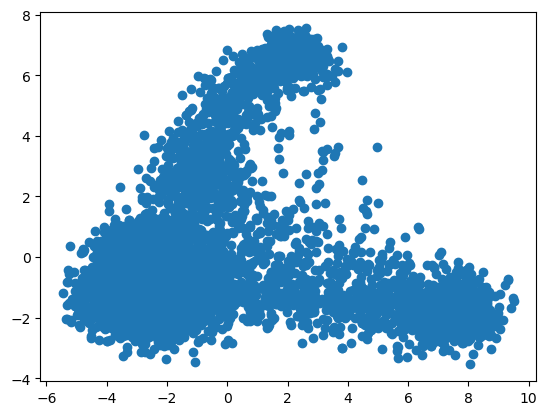

In [5]:
plt.scatter(adata_rna_all_lin.obsm["X_pca"][:,0], adata_rna_all_lin.obsm["X_pca"][:,1])

In [6]:
myeloid_cells = adata_rna_all_lin.obs_names.values[adata_rna_all_lin.obsm["X_pca"][:,1]<=1]
adata_atac = adata_atac_all_lin[myeloid_cells,:]
adata_rna = adata_rna_all_lin[myeloid_cells,:]

In [7]:
X_pca = adata_rna.obsm["X_pca"]

In [8]:
atac_df = pd.DataFrame(data=adata_atac.X, index=adata_atac.obs_names.values, columns=adata_atac.var_names.values)
rna_df = pd.DataFrame(data=adata_rna.X.toarray(), index=adata_rna.obs_names.values, columns=adata_rna.var_names.values)

In [9]:
def minmax_cols(df):
    mn, mx = df.min(axis=0), df.max(axis=0)
    rng = (mx - mn).replace(0, np.nan)   # constant columns would divide by zero
    return ((df - mn) / rng).fillna(0)

atac_df = minmax_cols(atac_df)
rna_df = minmax_cols(rna_df)

In [10]:
def gaussian_smooth_on_grid(x, y, grid):
    sigma = 0.1 * (grid.max() - grid.min())
    x, y, grid = map(np.asarray, (x, y, grid))
    w = np.exp(-0.5 * ((grid[:, None] - x[None, :]) / sigma) ** 2)  # (n_grid, n_points)
    return ((w @ y) / w.sum(axis=1)).tolist()

def monotonic(x, eps=0.1):
    dx = np.diff(x)
    return np.all(dx >= -eps) or np.all(dx <= eps)

def monotonicity(y, min_range=0.05):
    y = np.asarray(y, float)
    rng = np.ptp(y)
    if np.isnan(y).any() or rng < min_range:
        return dict(reversal=np.nan, direction=0, ptp=rng)
    drawdown = np.max(np.maximum.accumulate(y) - y)   # largest fall after a peak (violates "increasing")
    drawup   = np.max(y - np.minimum.accumulate(y))   # largest rise after a trough (violates "decreasing")
    return dict(reversal=min(drawdown, drawup) / rng,
                direction=1 if drawdown < drawup else -1,
                ptp=rng)

In [11]:
gridsize = 25

In [12]:
monotonic_genes = {}
non_monotonic_genes = {}
skipped_zero = []

grid = np.linspace(X_pca[:,0].min(), X_pca[:,0].max(), gridsize)

for i, gene_name in enumerate(rna_df.columns):
    if (atac_df.iloc[:, i] == 0).all() or (rna_df.iloc[:, i] == 0).all():
        skipped_zero.append(gene_name)
        continue

    smoothed_atac = gaussian_smooth_on_grid(X_pca[:,0], atac_df.iloc[:, i], grid)
    smoothed_rna  = gaussian_smooth_on_grid(X_pca[:,0], rna_df.iloc[:, i], grid)

    eps_r, eps_a = 0.05 * np.ptp(smoothed_rna), 0.05 * np.ptp(smoothed_atac)

    entry = {"smooth_rna": smoothed_rna,
             "smooth_atac": smoothed_atac,
             "rel_eps_rna": eps_r,
             "rel_eps_atac": eps_a}

    if monotonic(smoothed_atac, eps=eps_a) and monotonic(smoothed_rna, eps=eps_r):
        monotonic_genes[gene_name] = entry
    else:
        non_monotonic_genes[gene_name] = entry

print("Monotonic:", len(monotonic_genes))
print("Non-monotonic:", len(non_monotonic_genes))
print("Skipped (all zero):", len(skipped_zero))
assert len(monotonic_genes) + len(non_monotonic_genes) + len(skipped_zero) == rna_df.shape[1]

Monotonic: 240
Non-monotonic: 372
Skipped (all zero): 64


In [13]:
def classify_shape(y, tol=0.1, min_range=0.05):
    m = monotonicity(y, min_range=min_range)
    if np.isnan(m["reversal"]):
        shape = "nan" if np.isnan(y).any() else "flat"
    elif m["reversal"] <= tol:
        shape = "up" if m["direction"] == 1 else "down"
    else:
        shape = "transient"
    return shape, m

TOL, MIN_RANGE = 0.1, 0.05

monotonic_genes = {}
non_monotonic_genes = {}
skipped_zero = []

grid = np.linspace(X_pca[:, 0].min(), X_pca[:, 0].max(), gridsize)

for i, gene_name in enumerate(rna_df.columns):
    if (atac_df.iloc[:, i] == 0).all() or (rna_df.iloc[:, i] == 0).all():
        skipped_zero.append(gene_name)
        continue

    smoothed_atac = np.asarray(gaussian_smooth_on_grid(X_pca[:, 0], atac_df.iloc[:, i], grid))
    smoothed_rna  = np.asarray(gaussian_smooth_on_grid(X_pca[:, 0], rna_df.iloc[:, i], grid))

    shape_r, m_r = classify_shape(smoothed_rna, TOL, MIN_RANGE)
    shape_a, m_a = classify_shape(smoothed_atac, TOL, MIN_RANGE)

    entry = {"smooth_rna": smoothed_rna,
             "smooth_atac": smoothed_atac,
             "rna_shape": shape_r, "atac_shape": shape_a,
             "rna_reversal": m_r["reversal"], "atac_reversal": m_a["reversal"],
             "rna_ptp": m_r["ptp"], "atac_ptp": m_a["ptp"]}

    if shape_r in ("up", "down") and shape_a in ("up", "down"):
        monotonic_genes[gene_name] = entry
    else:
        non_monotonic_genes[gene_name] = entry

print("Monotonic:", len(monotonic_genes))
print("Non-monotonic:", len(non_monotonic_genes))
print("Skipped (all zero):", len(skipped_zero))
assert len(monotonic_genes) + len(non_monotonic_genes) + len(skipped_zero) == rna_df.shape[1]

shapes = pd.DataFrame({g: (d["rna_shape"], d["atac_shape"])
                       for g, d in {**monotonic_genes, **non_monotonic_genes}.items()},
                      index=["rna_shape", "atac_shape"]).T
print(pd.crosstab(shapes.rna_shape, shapes.atac_shape))

Monotonic: 112
Non-monotonic: 500
Skipped (all zero): 64
atac_shape  down  flat  transient  up
rna_shape                            
down          37   143         17  14
flat           6   106         14  23
transient      3    61         12  24
up             2    81         10  59


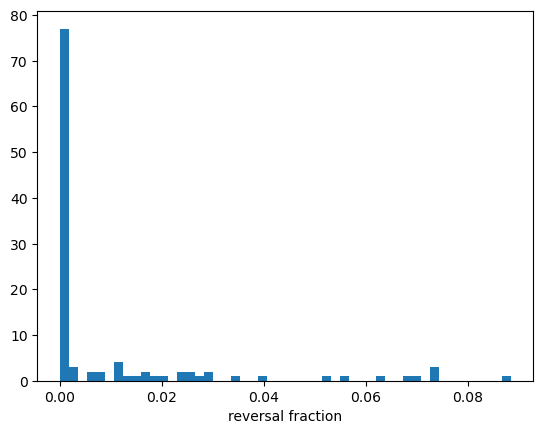

In [14]:
stats = pd.DataFrame({g: monotonicity(d["smooth_rna"]) for g, d in monotonic_genes.items()}).T
plt.hist(stats["reversal"].astype(float), bins=50); plt.xlabel("reversal fraction"); plt.show()

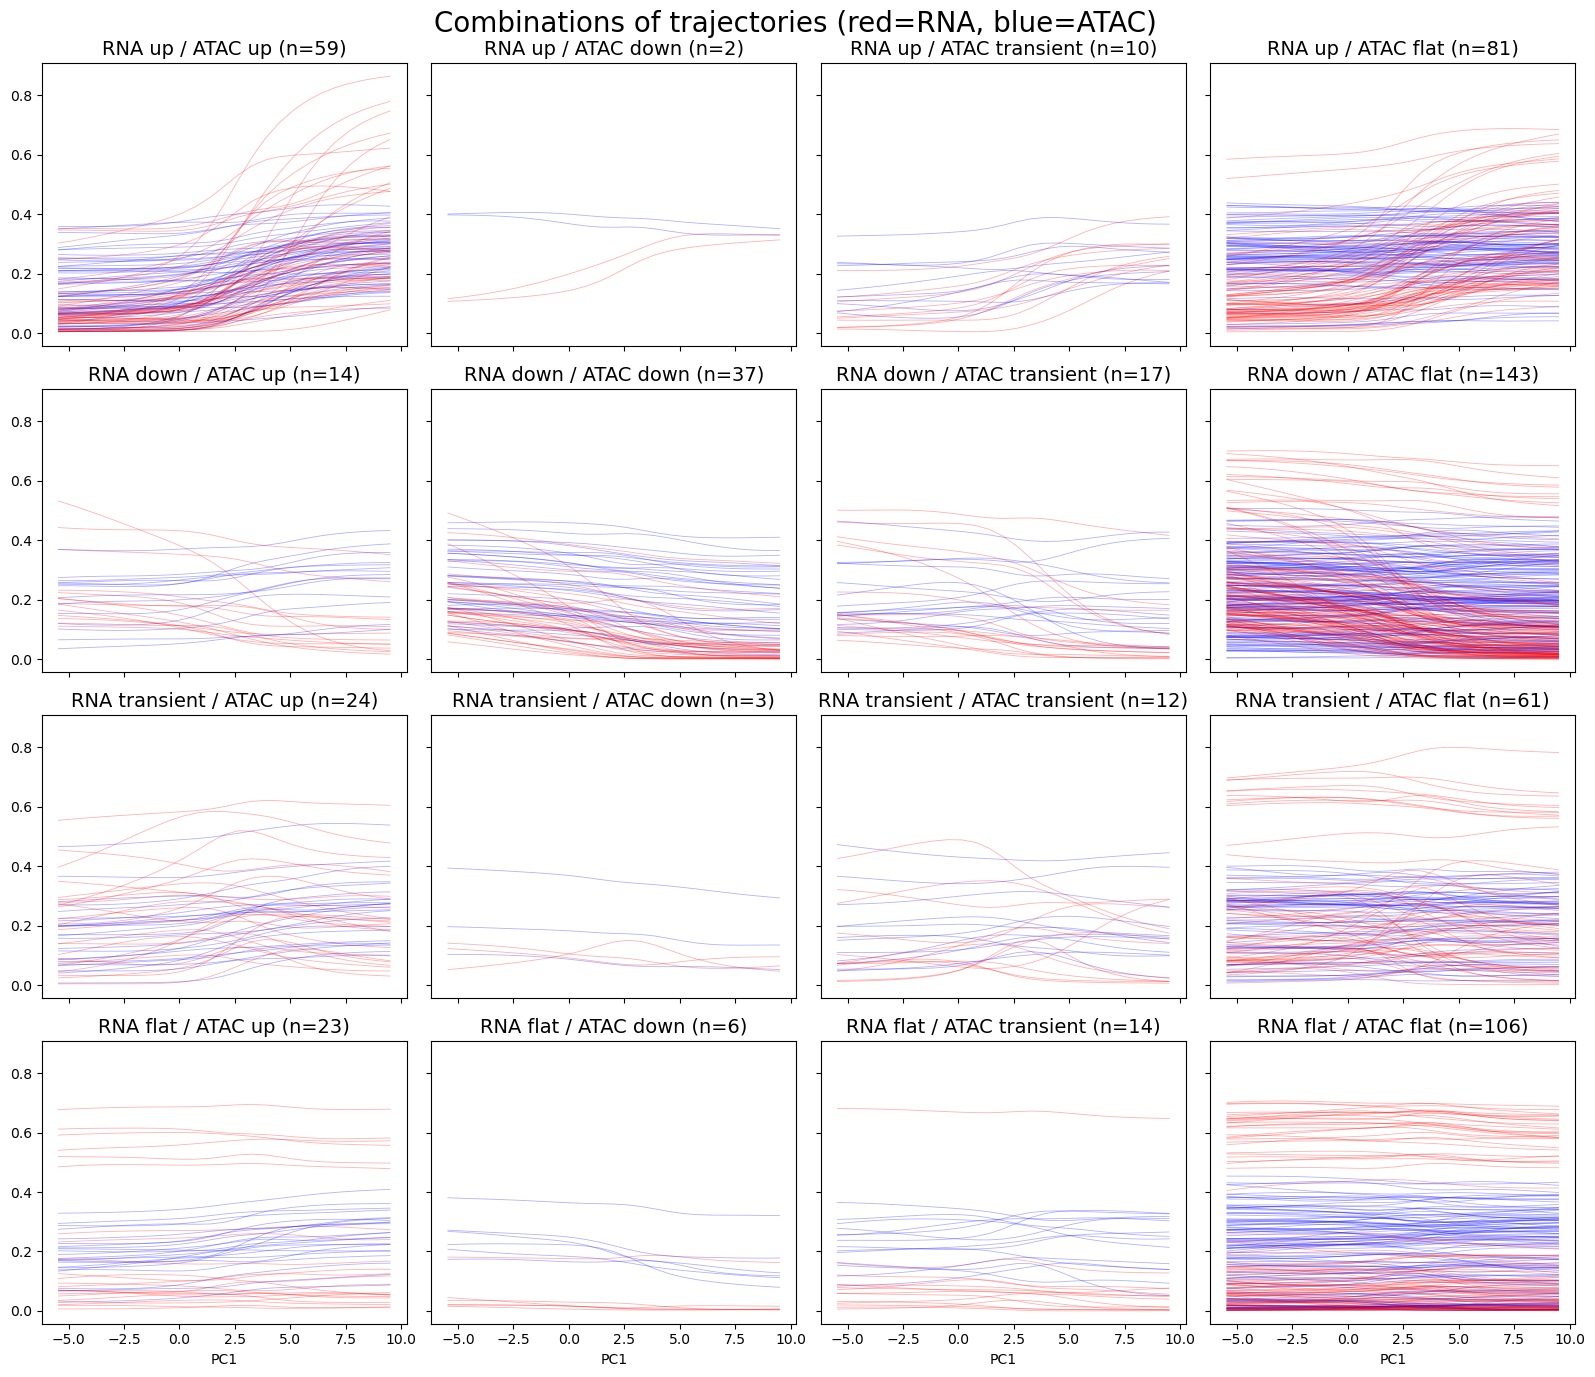

In [14]:
all_genes = {**monotonic_genes, **non_monotonic_genes}
shape_order = ["up", "down", "transient", "flat"]

fig, axs = plt.subplots(4, 4, figsize=(16, 14), sharex=True, sharey=True)

for i, rs in enumerate(shape_order):          # rows: RNA shape
    for j, a_s in enumerate(shape_order):     # columns: ATAC shape
        ax = axs[i, j]
        genes = [g for g, d in all_genes.items() if d["rna_shape"] == rs and d["atac_shape"] == a_s]
        for g in genes:
            ax.plot(grid, all_genes[g]["smooth_rna"],  color="red",  lw=0.6, alpha=0.3)
            ax.plot(grid, all_genes[g]["smooth_atac"], color="blue", lw=0.6, alpha=0.3)
        ax.set_title(f"RNA {rs} / ATAC {a_s} (n={len(genes)})", fontsize=14)

for ax in axs[-1]: ax.set_xlabel("PC1")
plt.suptitle("Combinations of trajectories (red=RNA, blue=ATAC)", fontsize=20)
plt.tight_layout()
plt.show()

Crucially, some of the curves look as through it would be best to remove the 0-count cells. However (!), here the importance of the ratio of count vs. 0-count cells becomes apparent, shaping the curve.

## Trying to identify clusters within the trajectories
First approach is to use only a few discriminant features, secondly we can try using the entire concatenated curves

I want to try a more naive approach and check certain properties of the curves, which can be combined combinatorially.

In [25]:
def half_max_pos(y, grid):  # Finds the midpoint in the grid between the minimum and maximum
    y = (y - y.min()) / (y.max() - y.min())
    return grid[np.argmin(np.abs(y - 0.5))]

t = (grid - grid.min()) / (grid.max() - grid.min())   # normalize time to 0-1

rows = []

for g, d in monotonic_genes.items():
    r, a = np.asarray(d["smooth_rna"]), np.asarray(d["smooth_atac"])

    rows.append(dict(gene=g,
                     monotonicity_r=monotonicity(r)["reversal"],
                     monotonicity_a=monotonicity(a)["reversal"],
                     rna_dir=np.sign(r[-1] - r[0]), 
                     atac_dir=np.sign(a[-1] - a[0]),
                     t_rna=half_max_pos(r, t), 
                     t_atac=half_max_pos(a, t),
                     # RNA
                     rna_max=np.max(r),
                     rna_max_idx=np.argmax(r)/gridsize,
                     rna_min=np.min(r),
                     rna_min_idx=np.argmin(r)/gridsize,
                     # ATAC
                     atac_max=np.max(a),
                     atac_max_idx=np.argmax(a)/gridsize,
                     atac_min=np.min(a),
                     atac_min_idx=np.argmin(a)/gridsize,
                     ))
    
feat = pd.DataFrame(rows).set_index("gene")
feat["lag"] = feat.t_atac - feat.t_rna
feat["lag_dir"] = np.sign(feat["lag"]).astype(int)

In [16]:
rna_dir = [1, -1]
atac_dir = [1, -1]
lag_dir = [1, -1, 0]

combinations = list(product(rna_dir, atac_dir, lag_dir))

In [17]:
curves = pd.DataFrame(
    {g: np.concatenate([d["smooth_rna"], d["smooth_atac"]]) for g, d in monotonic_genes.items()},
    index=[f"rna_{i}" for i in range(len(grid))] + [f"atac_{i}" for i in range(len(grid))],
).T

Combiantion RNA 1 / ATAC -1 / lag 0 not found.


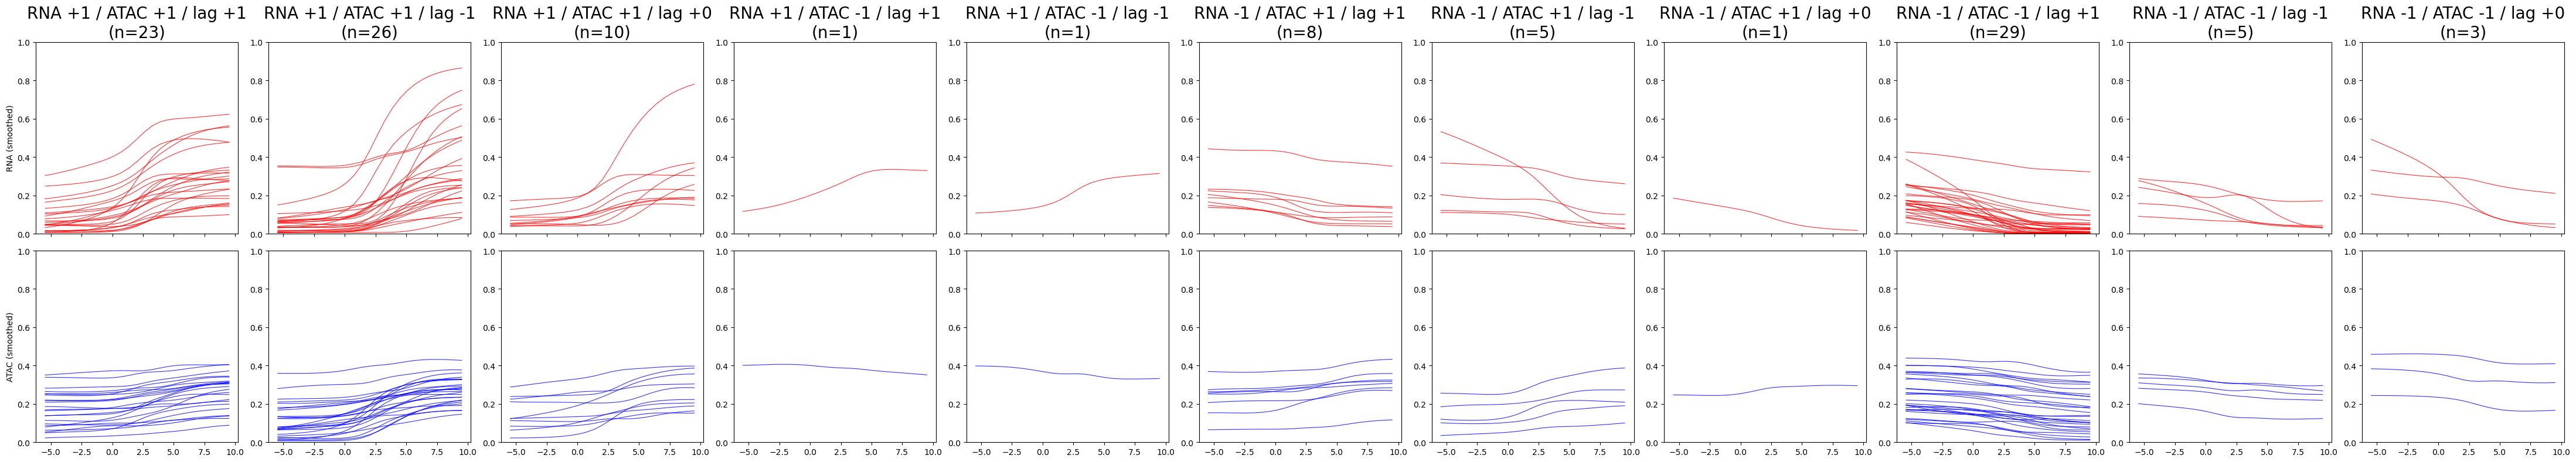

In [18]:
n = len(grid)

# 1) computation: collect non-empty groups
groups = {}
for r_dir, a_dir, l_dir in combinations:
    mask = (feat["rna_dir"] == r_dir) & (feat["atac_dir"] == a_dir) & (feat["lag_dir"] == l_dir)
    genes = feat.index[mask]
    if len(genes) > 0:
        groups[(r_dir, a_dir, l_dir)] = curves.loc[genes].values
    else: 
        print(f"Combiantion RNA {r_dir} / ATAC {a_dir} / lag {l_dir} not found.")

# 2) plotting: one column per non-empty group
fig, axs = plt.subplots(nrows=2, ncols=len(groups), figsize=(len(groups)*4, 8),
                        sharex=True, squeeze=False)

for i, ((r_dir, a_dir, l_dir), subset) in enumerate(groups.items()):
    for row in subset:
        axs[0, i].plot(grid, row[:n], color="red", lw=0.8, alpha=0.8)
        axs[0, i].set_ylim(0,1)
        axs[1, i].plot(grid, row[n:], color="blue", lw=0.8, alpha=0.8)
        axs[1, i].set_ylim(0,1)
    axs[0, i].set_title(f"RNA {r_dir:+d} / ATAC {a_dir:+d} / lag {l_dir:+d}\n(n={len(subset)})", fontsize=20)

axs[0, 0].set_ylabel("RNA (smoothed)")
axs[1, 0].set_ylabel("ATAC (smoothed)")
plt.tight_layout()
plt.show()

Other visual

In [20]:
n = len(grid)

def mm(A):  # per-gene min-max, so each row spans 0-1
    return (A - A.min(1, keepdims=True)) / np.maximum(np.ptp(A, axis=1, keepdims=True), 1e-12)

# order genes: by direction group, then by RNA half-max position
order = feat.sort_values(["rna_dir", "atac_dir", "t_rna"]).index
X = curves.loc[order].values
R, A = mm(X[:, :n]), mm(X[:, n:])          # (n_genes, n) each
extent = [grid.min(), grid.max(), len(order), 0]

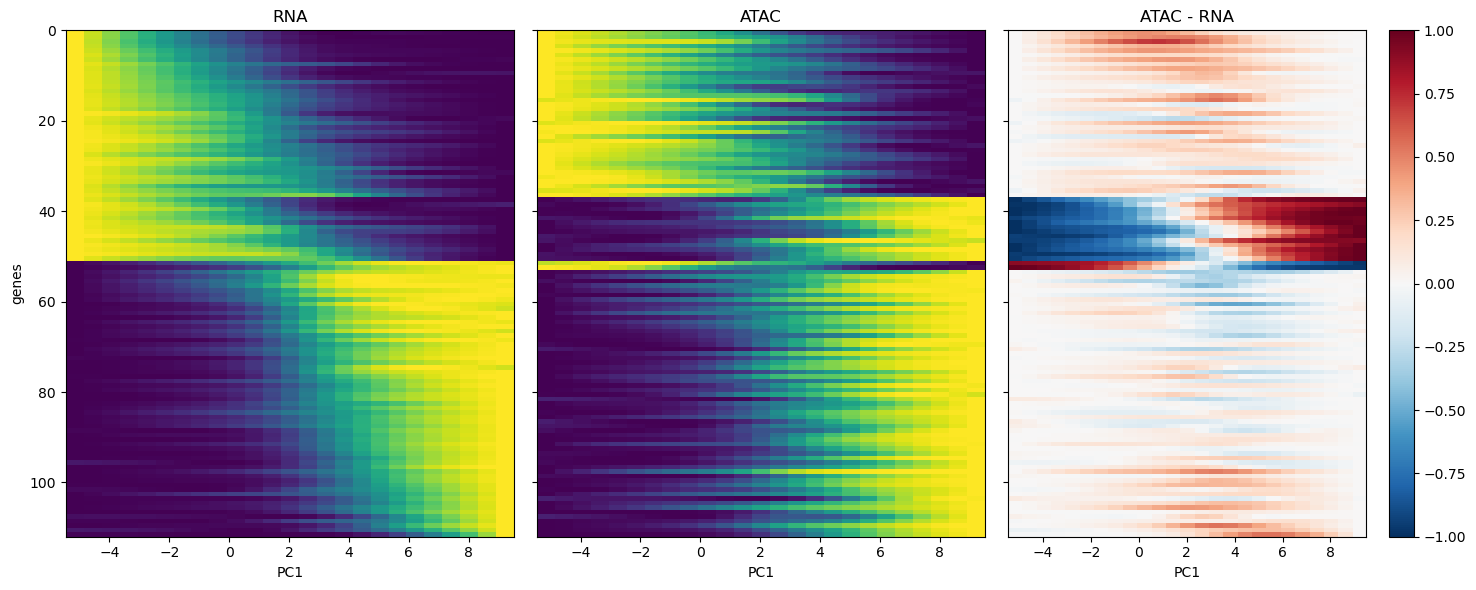

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
axs[0].imshow(R, aspect="auto", cmap="viridis", extent=extent); axs[0].set_title("RNA")
axs[1].imshow(A, aspect="auto", cmap="viridis", extent=extent); axs[1].set_title("ATAC")
im = axs[2].imshow(A - R, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, extent=extent)
axs[2].set_title("ATAC - RNA"); plt.colorbar(im, ax=axs[2])
for ax in axs: ax.set_xlabel("PC1")
axs[0].set_ylabel("genes")
plt.tight_layout(); plt.show()

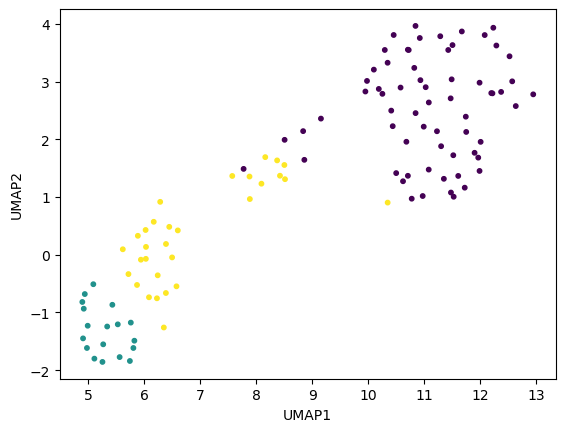

In [22]:
cols = ["t_rna", "t_atac", "lag", "rna_max", "atac_max", "rna_max_idx", "atac_max_idx", "rna_min", "atac_min",
        "rna_min_idx", "atac_min_idx"]

Z = StandardScaler().fit_transform(feat[cols])
feat["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

# P = PCA(n_components=2).fit(Z)
# emb = P.transform(Z)

# plt.scatter(emb[:, 0], emb[:, 1], c=feat["cluster"], cmap="Spectral", s=10)
# plt.xlabel(f"PC1 ({P.explained_variance_ratio_[0]:.0%})")
# plt.ylabel(f"PC2 ({P.explained_variance_ratio_[1]:.0%})")
# plt.show()

emb = umap.UMAP(n_neighbors=20, min_dist=0.1, random_state=0).fit_transform(Z)

plt.scatter(emb[:, 0], emb[:, 1], c=feat["cluster"], cmap="viridis", s=10)
plt.xlabel("UMAP1"); plt.ylabel("UMAP2")
plt.show()

In [23]:
m = feat[feat["cluster"].isin([0, 1])].groupby("cluster")[cols].mean().T
m["diff (1 - 0)"] = m[1] - m[0]
m["abs diff"] = m["diff (1 - 0)"].abs()
print(m.sort_values("abs diff", ascending=False).round(3))

cluster           0      1  diff (1 - 0)  abs diff
atac_max_idx  0.942  0.031        -0.911     0.911
atac_min_idx  0.068  0.940         0.872     0.872
rna_max_idx   0.852  0.000        -0.852     0.852
rna_min_idx   0.126  0.902         0.776     0.776
t_rna         0.590  0.343        -0.247     0.247
lag          -0.005  0.185         0.190     0.190
rna_max       0.320  0.157        -0.163     0.163
atac_max      0.260  0.177        -0.083     0.083
rna_min       0.076  0.015        -0.061     0.061
t_atac        0.585  0.528        -0.057     0.057
atac_min      0.139  0.093        -0.046     0.046


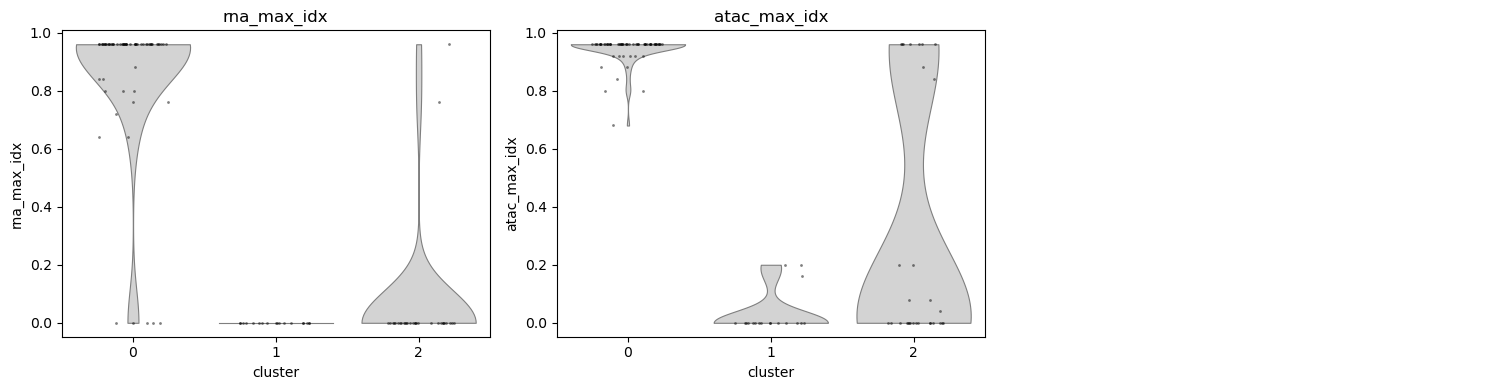

In [24]:
cols_plot = ["rna_max_idx", "atac_max_idx"]          # continuous features only
d = feat[feat["cluster"].isin([0, 1, 2])]

ncol = 3
nrow = int(np.ceil(len(cols_plot) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow))

for ax, c in zip(axs.ravel(), cols_plot):
    sns.violinplot(data=d, x="cluster", y=c, inner=None, cut=0, color="lightgray",
                   linewidth=0.8, density_norm="width", ax=ax)
    sns.stripplot(data=d, x="cluster", y=c, size=2, alpha=0.5, jitter=0.25,
                  color="black", ax=ax)
    ax.set_title(c)
for ax in axs.ravel()[len(cols_plot):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Non-Monotonic Genes
Repeat previous analysis for the other part of the genes

In [25]:
rows_nm = []

for g, d in non_monotonic_genes.items():
    r, a = np.asarray(d["smooth_rna"]), np.asarray(d["smooth_atac"])
    
    rows_nm.append(dict(gene=g,
                        monotonicity_r=monotonicity(r)["reversal"],
                        monotonicity_a=monotonicity(a)["reversal"],
                     rna_dir=np.sign(r[-1] - r[0]), 
                     atac_dir=np.sign(a[-1] - a[0]),
                     t_rna=half_max_pos(r, t), 
                     t_atac=half_max_pos(a, t),
                     # RNA
                     rna_max=np.max(r),
                     rna_max_idx=np.argmax(r)/gridsize,
                     rna_min=np.min(r),
                     rna_min_idx=np.argmin(r)/gridsize,
                     # ATAC
                     atac_max=np.max(a),
                     atac_max_idx=np.argmax(a)/gridsize,
                     atac_min=np.min(a),
                     atac_min_idx=np.argmin(a)/gridsize,
                     ))
    
feat_nm = pd.DataFrame(rows_nm).set_index("gene")
feat_nm["lag"] = feat_nm.t_atac - feat_nm.t_rna
feat_nm["lag_dir"] = np.sign(feat_nm["lag"]).astype(int)

In [26]:
curves_nm = pd.DataFrame(
    {g: np.concatenate([d["smooth_rna"], d["smooth_atac"]]) for g, d in non_monotonic_genes.items()},
    index=[f"rna_{i}" for i in range(len(grid))] + [f"atac_{i}" for i in range(len(grid))],
).T

In [27]:
n = len(grid)

def mm(A):  # per-gene min-max, so each row spans 0-1
    return (A - A.min(1, keepdims=True)) / np.maximum(np.ptp(A, axis=1, keepdims=True), 1e-12)

order = feat_nm.sort_values(["rna_max_idx", "atac_max_idx", "t_rna"]).index
X = curves_nm.loc[order].values
R, A = mm(X[:, :n]), mm(X[:, n:])
extent = [grid.min(), grid.max(), len(order), 0]

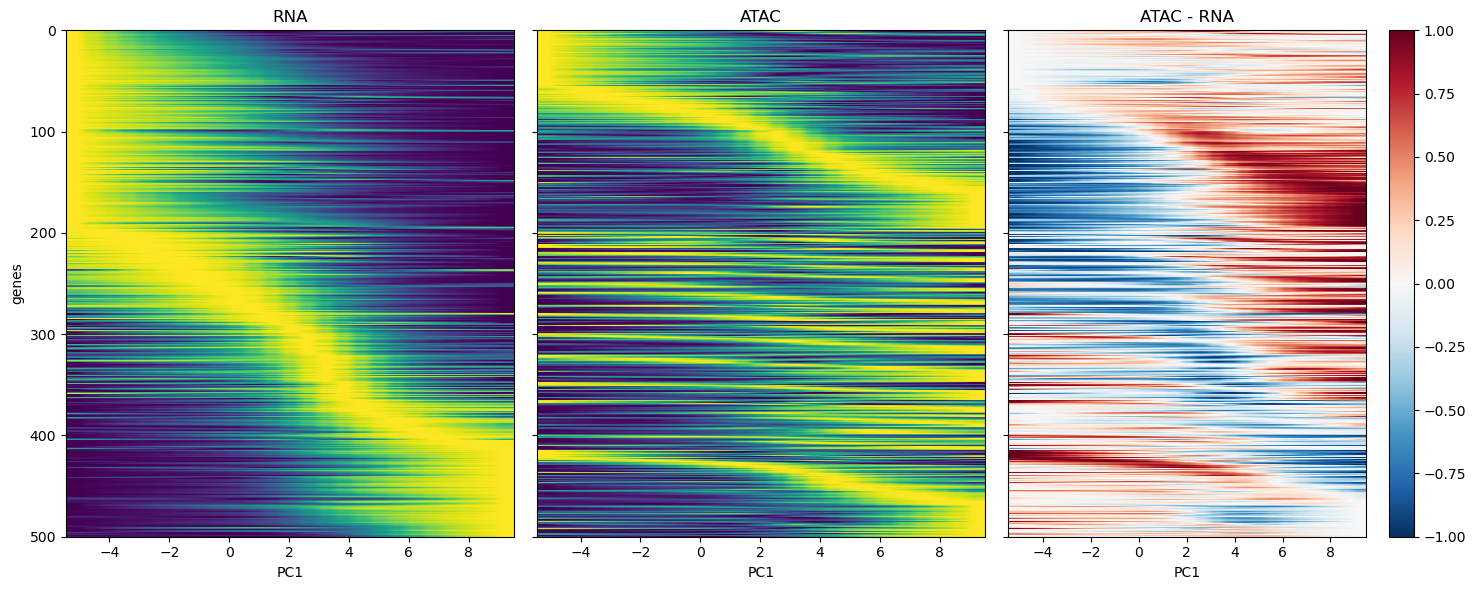

In [28]:
fig, axs = plt.subplots(1, 3, figsize=(15, 6), sharey=True)

axs[0].imshow(R, aspect="auto", cmap="viridis", extent=extent); axs[0].set_title("RNA")
axs[1].imshow(A, aspect="auto", cmap="viridis", extent=extent); axs[1].set_title("ATAC")
im = axs[2].imshow(A - R, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, extent=extent)
axs[2].set_title("ATAC - RNA"); plt.colorbar(im, ax=axs[2])

for ax in axs: ax.set_xlabel("PC1")

axs[0].set_ylabel("genes")
plt.tight_layout(); plt.show()

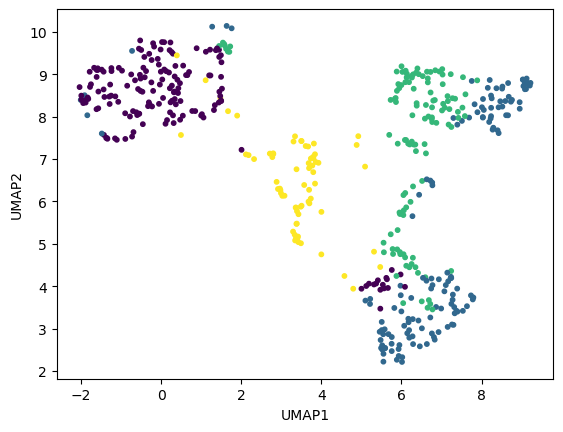

In [29]:
X = feat_nm[cols].dropna()
Z = StandardScaler().fit_transform(X)

feat_nm["cluster"] = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(Z)

emb = umap.UMAP(n_neighbors=20, min_dist=0.1, random_state=0).fit_transform(Z)

plt.scatter(emb[:, 0], emb[:, 1], c=feat_nm["cluster"], cmap="viridis", s=10)
plt.xlabel("UMAP1"); plt.ylabel("UMAP2")
plt.show()

In [30]:
m = feat_nm[feat_nm["cluster"].isin([0, 1, 2])].groupby("cluster")[cols].mean().T
m["diff (1 - 0)"] = m[1] - m[0]
m["abs diff"] = m["diff (1 - 0)"].abs()
print(m.sort_values("abs diff", ascending=False).round(3))

cluster           0      1      2  diff (1 - 0)  abs diff
rna_min_idx   0.155  0.853  0.830         0.698     0.698
rna_max_idx   0.773  0.130  0.130        -0.643     0.643
atac_max_idx  0.758  0.541  0.328        -0.217     0.217
atac_min_idx  0.227  0.433  0.650         0.206     0.206
lag          -0.056  0.098  0.102         0.154     0.154
t_rna         0.594  0.443  0.450        -0.151     0.151
atac_max      0.254  0.128  0.326        -0.126     0.126
atac_min      0.211  0.090  0.287        -0.121     0.121
rna_max       0.242  0.146  0.213        -0.096     0.096
rna_min       0.107  0.044  0.105        -0.063     0.063
t_atac        0.538  0.541  0.552         0.003     0.003


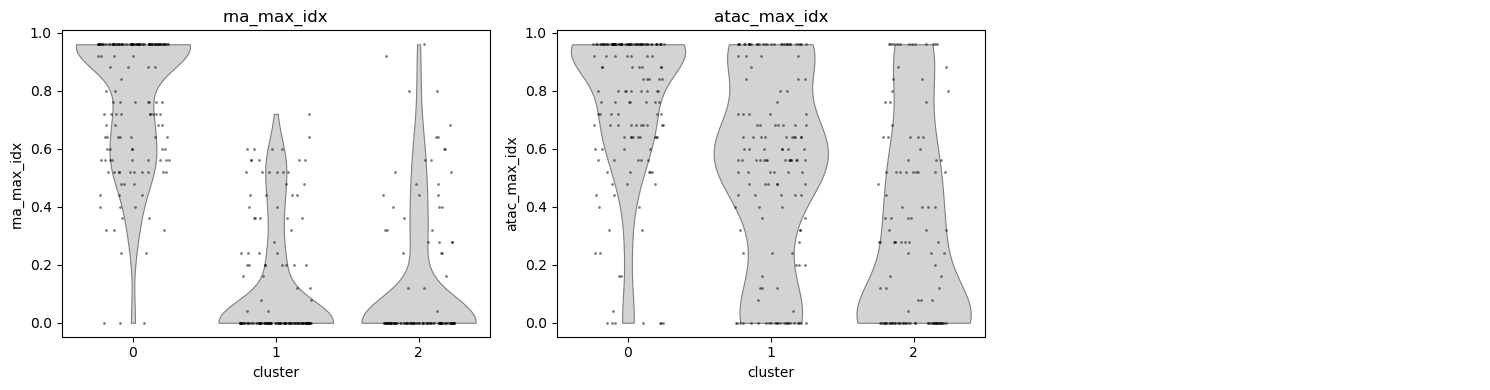

In [31]:
cols_plot = ["rna_max_idx", "atac_max_idx"]          # continuous features only
d = feat_nm[feat_nm["cluster"].isin([0, 1, 2])]

ncol = 3
nrow = int(np.ceil(len(cols_plot) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow))

for ax, c in zip(axs.ravel(), cols_plot):
    sns.violinplot(data=d, x="cluster", y=c, inner=None, cut=0, color="lightgray",
                   linewidth=0.8, density_norm="width", ax=ax)
    sns.stripplot(data=d, x="cluster", y=c, size=2, alpha=0.5, jitter=0.25,
                  color="black", ax=ax)
    ax.set_title(c)
for ax in axs.ravel()[len(cols_plot):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Perform previous analyses across all genes! 

In [19]:
all_genes = monotonic_genes | non_monotonic_genes

rows_all = []

for g, d in all_genes.items():
    r, a = np.asarray(d["smooth_rna"]), np.asarray(d["smooth_atac"])
    
    rows_all.append(dict(gene=g,
                    monotonicity_r=monotonicity(r)["reversal"],
                    monotonicity_a=monotonicity(a)["reversal"],
                     rna_dir=np.sign(r[-1] - r[0]), 
                     atac_dir=np.sign(a[-1] - a[0]),
                     t_rna=half_max_pos(r, t), 
                     t_atac=half_max_pos(a, t),
                     # RNA
                     rna_max=np.max(r),
                     rna_max_idx=np.argmax(r)/gridsize,
                     rna_min=np.min(r),
                     rna_min_idx=np.argmin(r)/gridsize,
                     # ATAC
                     atac_max=np.max(a),
                     atac_max_idx=np.argmax(a)/gridsize,
                     atac_min=np.min(a),
                     atac_min_idx=np.argmin(a)/gridsize,
                     ))
    
feat_all = pd.DataFrame(rows_all).set_index("gene")
feat_all["lag"] = feat_all.t_atac - feat_all.t_rna
feat_all["lag_dir"] = np.sign(feat_all["lag"]).astype(int)

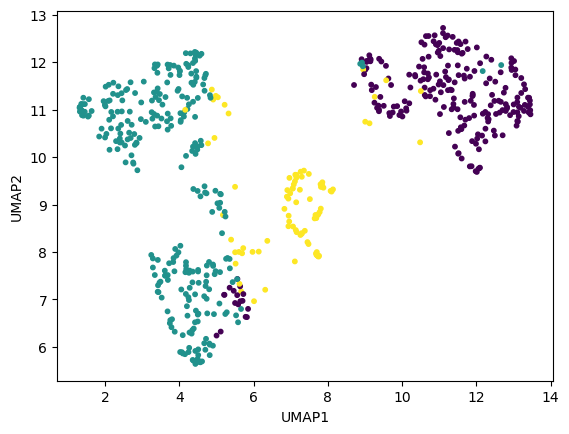

In [33]:
X = feat_all[cols].dropna()
Z = StandardScaler().fit_transform(X)

feat_all["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

emb = umap.UMAP(n_neighbors=20, min_dist=0.1, random_state=0).fit_transform(Z)

plt.scatter(emb[:, 0], emb[:, 1], c=feat_all["cluster"], cmap="viridis", s=10)
plt.xlabel("UMAP1"); plt.ylabel("UMAP2")
plt.show()

In [34]:
m = feat_all[feat_all["cluster"].isin([0, 1, 2])].groupby("cluster")[cols].mean().T
m["diff (1 - 0)"] = m[1] - m[0]
m["abs diff"] = m["diff (1 - 0)"].abs()
print(m.sort_values("abs diff", ascending=False).round(3))

cluster           0      1      2  diff (1 - 0)  abs diff
rna_min_idx   0.128  0.877  0.748         0.748     0.748
rna_max_idx   0.808  0.091  0.327        -0.717     0.717
atac_max_idx  0.792  0.406  0.577        -0.386     0.386
atac_min_idx  0.200  0.569  0.447         0.369     0.369
t_rna         0.590  0.438  0.556        -0.152     0.152
lag          -0.035  0.104 -0.082         0.139     0.139
rna_max       0.260  0.171  0.564        -0.088     0.088
atac_max      0.256  0.217  0.325        -0.039     0.039
rna_min       0.097  0.060  0.485        -0.037     0.037
atac_min      0.192  0.172  0.289        -0.020     0.020
t_atac        0.555  0.542  0.474        -0.013     0.013


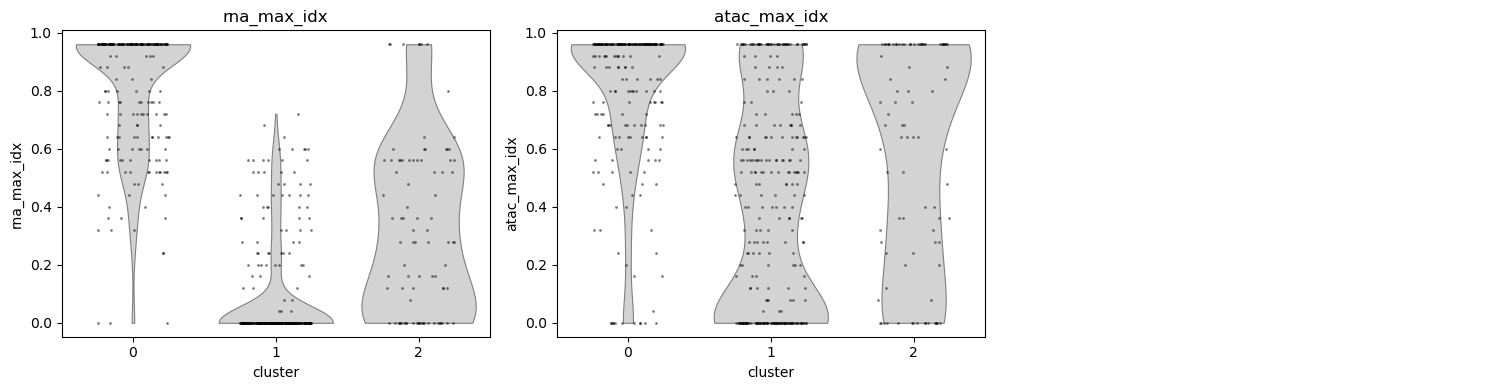

In [35]:
cols = ["rna_max_idx", "atac_max_idx"]          # continuous features only
d = feat_all[feat_all["cluster"].isin([0, 1, 2])]

ncol = 3
nrow = int(np.ceil(len(cols) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow))

for ax, c in zip(axs.ravel(), cols):
    sns.violinplot(data=d, x="cluster", y=c, inner=None, cut=0, color="lightgray",
                   linewidth=0.8, density_norm="width", ax=ax)
    sns.stripplot(data=d, x="cluster", y=c, size=2, alpha=0.5, jitter=0.25,
                  color="black", ax=ax)
    ax.set_title(c)
for ax in axs.ravel()[len(cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Analysis of pseudotime lag

In [29]:
feat_all["lag_max"] = feat_all.atac_max_idx - feat_all.rna_max_idx
lag_sorted_feats = feat.sort_values(["lag"], ascending=False)
pca_data = adata_rna.obsm["X_pca"][:,:2]

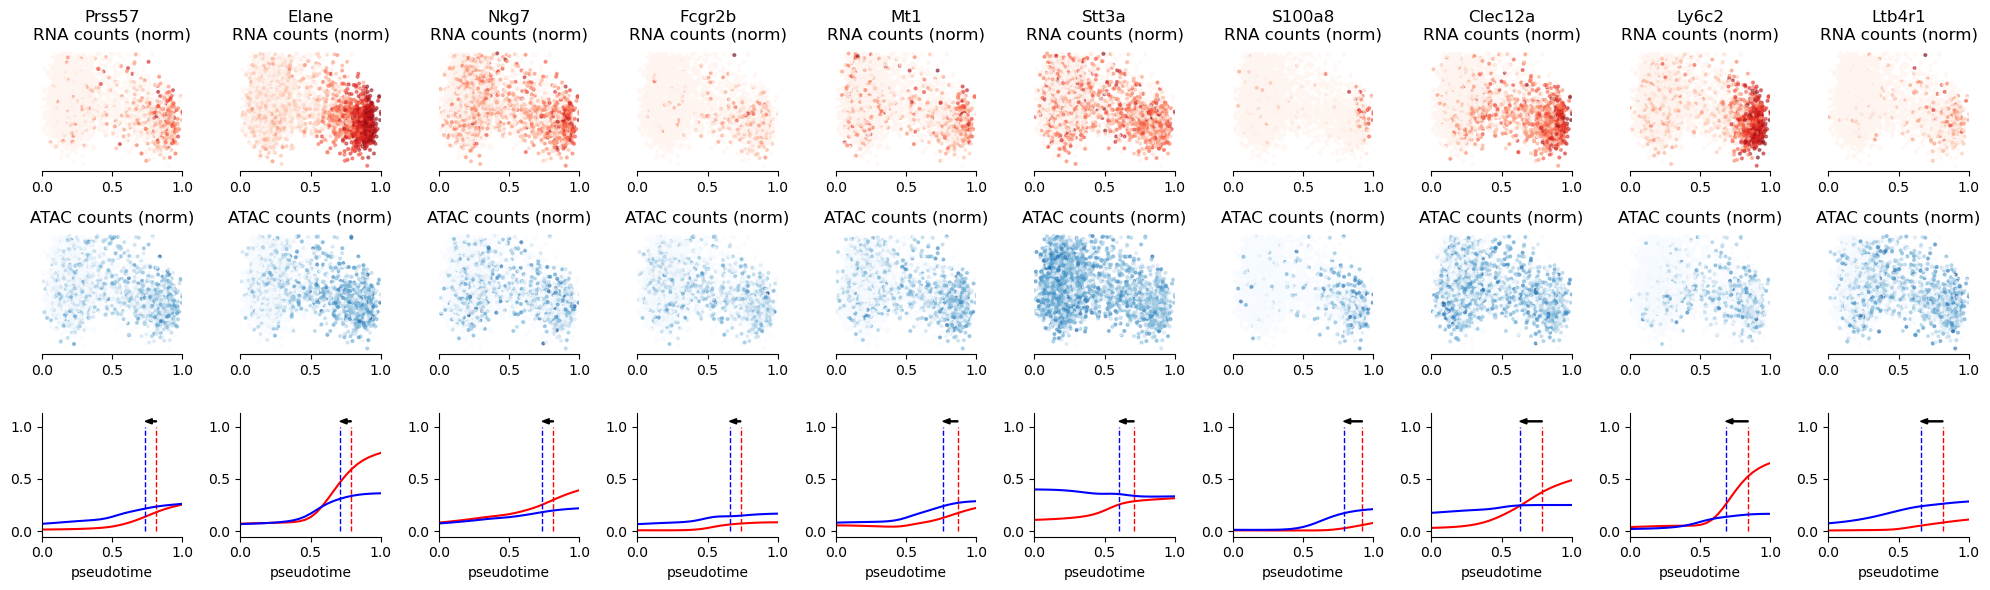

In [ ]:
num_genes = 10

min_x = np.min(pca_data[:, 0])
max_x = np.max(pca_data[:, 0])
x_norm = (pca_data[:, 0] - min_x) / (max_x - min_x)

grid_norm = np.linspace(0, 1, 25)

fig, axs = plt.subplots(nrows=3, ncols=num_genes, figsize=(num_genes*2, 6))

for i, gene in enumerate(lag_sorted_feats.index.tolist()[-num_genes:]):

    axs[0, i].scatter(x_norm, pca_data[:, 1], c=adata_rna[:, gene].X.toarray(), cmap="Reds", s=4, alpha=0.5)
    axs[0, i].set_title(f"{gene}\nRNA counts (norm)", fontsize=12)

    axs[1, i].scatter(x_norm, pca_data[:, 1], c=adata_atac[:, gene].X.toarray(), cmap="Blues", s=4, alpha=0.5)
    axs[1, i].set_title("ATAC counts (norm)", fontsize=12)

    for r in (0, 1):
        axs[r, i].spines[['left', 'top', 'right']].set_visible(False)
        axs[r, i].get_yaxis().set_visible(False)

    curve_data = curves.loc[gene, :].values

    t_rna = (feat.loc[gene, "t_rna"] * max_x - min_x) / (max_x - min_x)
    t_atac = (feat.loc[gene, "t_atac"] * max_x - min_x) / (max_x - min_x)

    axs[2, i].plot(grid_norm, curve_data[:25], c="red")
    axs[2, i].plot(grid_norm, curve_data[25:], c="blue")
    axs[2, i].vlines(t_rna, ymin=0, ymax=1, color="red", zorder=1, linestyle="dashed", linewidth=1)
    axs[2, i].vlines(t_atac, ymin=0, ymax=1, color="blue", zorder=2, linestyle="dashed", linewidth=1)
    axs[2, i].arrow(t_rna, 1.05, t_atac - t_rna, 0, zorder=0, width=0.01,
                    head_width=0.05, head_length=0.05,  
                    facecolor="black", length_includes_head=True)

    axs[2, i].spines[['top', 'right']].set_visible(False)

    for r in range(3):
        axs[r, i].set_xlim(0, 1)
    axs[2, i].set_xlabel("pseudotime")

plt.tight_layout()
plt.show()

## Chromatin Velocity
Clearly some of the genes follow the expected behavior that is assumed by chromatin velocity. We subset to this set of genes and then compute our velocities.

In [104]:
# Load z-score data and compute correlations with aggregated peak data
z_scores = sc.read_h5ad(rf"{python_data_dir}\z_scores_raw.h5ad")
z_scores.obs_names = [i[9:-2] for i in z_scores.obs_names.values]
z_scores = z_scores[z_scores.obs_names.isin(rna_df.index.values),:]
z_scores = pd.DataFrame(z_scores.X, index=z_scores.obs_names.values, columns=z_scores.var_names.values)

z_scores = minmax_cols(z_scores)

In [105]:
mono_atac_curves = curves.iloc[curves.index.isin(list(monotonic_genes.keys())), gridsize:]

In [106]:
z_score_curves = pd.DataFrame(np.zeros(shape=(len(z_scores.T), gridsize)), index=z_scores.columns, columns=[f"z_{i}" for i in range(gridsize)])

In [107]:
assert (rna_df.index.values == z_scores.index.values).all()

In [108]:
skipped_zero = []

for gene in z_score_curves.index.values: 
    
    if (z_scores.loc[:,gene] == 0).all():
        skipped_zero.append(gene)
        continue
    
    z_score_curves.loc[gene,:] = np.asarray(gaussian_smooth_on_grid(X_pca[:, 0], z_scores.loc[:,gene], grid))

In [109]:
A = mono_atac_curves.values   # (n_atac_genes, n_points)
Z = z_score_curves.values     # (n_z_genes, n_points)

# Standardize each row (mean 0, std 1)
A_std = (A - A.mean(axis=1, keepdims=True)) / A.std(axis=1, keepdims=True)
Z_std = (Z - Z.mean(axis=1, keepdims=True)) / Z.std(axis=1, keepdims=True)

# Pearson r for every (atac gene, z gene) pair
corrs = pd.DataFrame(
    A_std @ Z_std.T / A.shape[1],
    index=mono_atac_curves.index,
    columns=z_score_curves.index,
)

In [111]:
corrs

,Arnt,Ahr::Arnt,Ddit3::Cebpa,Mecom,FOXF2,FOXD1,Foxq1,Foxd3,IRF2,MZF1(var.2),...,TEAD1,TEAD4,TFAP2A,TFAP2C(var.2),TWIST1,USF1,USF2,YY2,ZNF263,CREM
Ptpn18,-0.885412,0.388603,-0.879908,0.469699,0.952553,0.991204,0.986355,0.981032,0.855144,0.473704,...,0.735987,0.616256,0.079867,-0.654590,-0.142466,-0.930221,-0.915300,-0.821091,-0.356379,-0.765862
Plcl1,-0.979343,0.083688,-0.971189,0.698667,0.976095,0.917365,0.885028,0.913073,0.868304,0.723971,...,0.485044,0.338930,0.022979,-0.827896,0.174965,-0.978109,-0.973941,-0.956968,-0.073071,-0.691145
Ikzf2,-0.984619,0.005256,-0.966130,0.757363,0.961797,0.893438,0.847875,0.868717,0.867280,0.787011,...,0.413486,0.272389,-0.008241,-0.871269,0.229820,-0.966170,-0.962523,-0.974494,0.033318,-0.618234
Gpc1,0.993991,0.052188,0.998419,-0.796771,-0.980568,-0.859498,-0.825261,-0.886951,-0.746206,-0.753947,...,-0.363818,-0.202091,-0.052403,0.868250,-0.307367,0.992872,0.996272,0.970948,0.030926,0.753807
Rgs18,-0.982332,-0.262083,-0.973954,0.904764,0.915341,0.750155,0.692329,0.757105,0.717729,0.889635,...,0.160885,0.001288,0.007981,-0.930163,0.488556,-0.941147,-0.949591,-0.994765,0.210921,-0.591911
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Ms4a3,0.990047,0.215069,0.987682,-0.883895,-0.938445,-0.779480,-0.727826,-0.795988,-0.727987,-0.857214,...,-0.209671,-0.047177,0.008355,0.928187,-0.449871,0.961253,0.968726,0.992126,-0.143688,0.648177
Hells,0.978437,-0.002188,0.969905,-0.741120,-0.959442,-0.879970,-0.838840,-0.872486,-0.877855,-0.777369,...,-0.407337,-0.260885,0.084966,0.881819,-0.246020,0.965808,0.963479,0.966997,-0.007033,0.645312
Tcf7l2,-0.956357,0.104676,-0.928240,0.688462,0.949138,0.928422,0.884069,0.878605,0.906954,0.733608,...,0.499583,0.374081,-0.011451,-0.829117,0.112214,-0.943698,-0.933944,-0.939637,-0.012492,-0.585085
Slc18a2,-0.929792,-0.304645,-0.897505,0.919947,0.849154,0.710773,0.634427,0.665286,0.695443,0.905089,...,0.106825,-0.026748,-0.016233,-0.926814,0.462147,-0.869885,-0.873967,-0.953265,0.332016,-0.439871


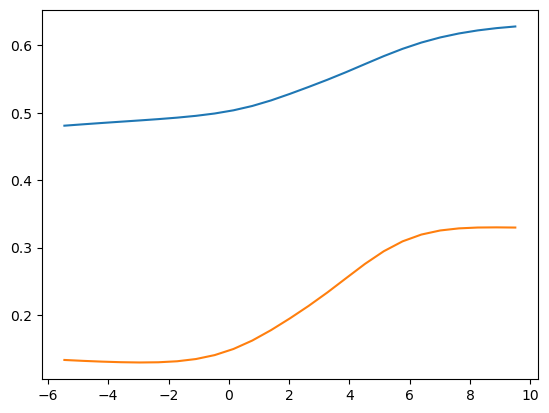

In [110]:
plt.plot(grid, z_score_curves.loc["Arnt",:])
plt.plot(grid, mono_atac_curves.loc["Gpc1",:])

Next I want to evaluate if I should just use the montonically increasing and lagging genes and then compute the correlations! 